# Exploración de los datos de Airbnb Bogotá

Taller 2 - Proceso ETL

En este notebook revisamos los datos antes de limpiarlos para entender qué traen y qué problemas tienen.
Los leemos desde MongoDB con la clase `Extraccion` de `src/extraccion.py`. Al final dejamos las decisiones
que después aplicamos en `src/transformacion.py`.

## 1. Carga de los datos

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# para poder importar lo que hay en la carpeta src
raiz = Path.cwd().resolve()
if raiz.name == "notebooks":
    raiz = raiz.parent
sys.path.append(str(raiz / "src"))

from extraccion import Extraccion

pd.set_option("display.max_columns", 30)

extractor = Extraccion(db_name="Airbnb")
extractor.conectar()
df_listings = extractor.extraer_datos("Listings")
df_reviews = extractor.extraer_datos("Reviews")
df_calendar = extractor.extraer_datos("Calendar")
extractor.cerrar()

2026-10-10 08:27:16 - INFO [etl.extraccion] Conexión a MongoDB (localhost:27017), base de datos 'Airbnb'.


2026-10-10 08:27:18 - INFO [etl.extraccion] Se extrajeron 19187 registros de la colección 'Listings'.


2026-10-10 08:27:24 - INFO [etl.extraccion] Se extrajeron 527731 registros de la colección 'Reviews'.


2026-10-10 08:27:58 - INFO [etl.extraccion] Se extrajeron 7003255 registros de la colección 'Calendar'.


2026-10-10 08:27:58 - INFO [etl.extraccion] Conexión a MongoDB cerrada.


## 2. Entendimiento de los datos

### Listings

In [2]:
print(df_listings.shape)
df_listings[["id", "name", "neighbourhood_cleansed", "room_type", "accommodates", "bedrooms", "price",
             "minimum_nights", "availability_365", "number_of_reviews"]].head()

(19187, 78)


,id,name,neighbourhood_cleansed,room_type,accommodates,bedrooms,price,minimum_nights,availability_365,number_of_reviews
0,27841,Rosales Luxury Large 2BR Boutique Apt,Chapinero,Entire home/apt,4,2.0,"$284,294.01",28.0,82,45
1,65762,Apartaestudios La Candelaria,Candelaria,Entire home/apt,3,1.0,"$215,000.00",1.0,236,33
2,138660,Excelent Studio ROSALES/ ZONA G,Chapinero,Entire home/apt,4,2.0,"$99,196.10",30.0,303,22
3,178850,"MODERN APARTMENT, 3 ROOMS, 4 PAX",Usaquen,Entire home/apt,4,3.0,"$179,910.67",30.0,353,3
4,289669,Room near to everything you need in Bogotá!,Teusaquillo,Private room,2,1.0,"$82,260.75",4.0,222,2


In [3]:
df_listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Data columns (total 78 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            19187 non-null  int64         
 1   listing_url                                   19187 non-null  str           
 2   scrape_id                                     19187 non-null  int64         
 3   last_scraped                                  19187 non-null  datetime64[us]
 4   source                                        19187 non-null  str           
 5   name                                          19187 non-null  object        
 6   description                                   18664 non-null  str           
 7   picture_url                                   19187 non-null  str           
 8   host_id                                       19187 non-null  int64         


In [4]:
df_listings[["accommodates", "bedrooms", "beds", "minimum_nights", "maximum_nights",
             "number_of_reviews", "review_scores_rating"]].describe()

,accommodates,bedrooms,beds,minimum_nights,maximum_nights,number_of_reviews,review_scores_rating
count,19187.000000,16228.000000,18896.000000,19183.000000,1.918300e+04,19187.000000,14922.000000
mean,3.105697,1.540670,1.945703,6.979878,4.485003e+05,27.504612,4.703524
std,2.088394,1.601175,2.094844,10.993985,3.100755e+07,74.004586,0.469821
min,1.000000,1.000000,1.000000,1.000000,2.000000e+00,0.000000,1.000000
25%,2.000000,1.000000,1.000000,1.000000,3.650000e+02,1.000000,4.640000
50%,2.000000,1.000000,1.000000,1.000000,3.650000e+02,8.000000,4.830000
75%,4.000000,2.000000,2.000000,3.000000,1.125000e+03,31.000000,4.980000
max,16.000000,50.000000,50.000000,32.000000,2.147484e+09,6162.000000,5.000000


**Interpretación.** Listings es la tabla principal: tiene 19.187 anuncios y 78 columnas, pero solo usamos unas 15
(zona, tipo de alojamiento, capacidad, precio, noches mínimas y reseñas). El resto son links, ids y datos de la consulta
de precios.

Notamos que `price` viene como texto con el signo `$` y comas, `amenities` es una lista y `price_quote_raw` es un
diccionario, así que hay que arreglarlos antes de usarlos. También vimos que `maximum_nights` llega a 2.147.483.647,
que no es una cantidad real de noches.

Por último, `number_of_reviews` tiene mediana 8 pero máximo 6.162: unos pocos anuncios tienen casi todas las reseñas.

### Reviews

In [5]:
print(df_reviews.shape)
print("Desde", df_reviews["date"].min().date(), "hasta", df_reviews["date"].max().date())
print("Anuncios con al menos una reseña:", df_reviews["listing_id"].nunique())
df_reviews.head()

(527731, 6)
Desde 2010-10-06 hasta 2026-06-21
Anuncios con al menos una reseña: 14922


,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."
3,27841,225796,2011-04-13,471115,Tiffany,Marcela was a lovely and gracious host. She me...
4,27841,952928,2012-02-27,1098411,Sarah,Marcela is the perfect host and has a gorgeuos...


In [6]:
df_reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   listing_id     527731 non-null  int64         
 1   id             527731 non-null  int64         
 2   date           527731 non-null  datetime64[us]
 3   reviewer_id    527731 non-null  int64         
 4   reviewer_name  527731 non-null  object        
 5   comments       527730 non-null  object        
dtypes: datetime64[us](1), int64(3), object(2)
memory usage: 24.2+ MB


**Interpretación.** Hay 527.731 reseñas entre 2010 y junio de 2026. `listing_id` sirve para unirlas con `Listings.id`.
Cerca del 78 % de los anuncios tiene al menos una reseña; el resto nunca ha tenido, y eso explica los nulos de las
calificaciones en Listings.

### Calendar

In [7]:
print(df_calendar.shape)
print("Desde", df_calendar["date"].min().date(), "hasta", df_calendar["date"].max().date())
print(df_calendar["available"].value_counts())
df_calendar.head()

(7003255, 5)
Desde 2026-06-21 hasta 2027-06-21
available
True     5890813
False    1112442
Name: count, dtype: int64


,listing_id,date,available,minimum_nights,maximum_nights
0,15410909,2026-06-22,False,2,1125
1,15410909,2026-06-23,False,2,1125
2,15410909,2026-06-24,False,2,1125
3,15410909,2026-06-25,True,2,1125
4,15410909,2026-06-26,True,2,1125


In [8]:
df_calendar.info()

<class 'pandas.DataFrame'>
RangeIndex: 7003255 entries, 0 to 7003254
Data columns (total 5 columns):
 #   Column          Dtype         
---  ------          -----         
 0   listing_id      int64         
 1   date            datetime64[us]
 2   available       bool          
 3   minimum_nights  int64         
 4   maximum_nights  int64         
dtypes: bool(1), datetime64[us](1), int64(3)
memory usage: 220.4 MB


**Interpretación.** Calendar tiene un registro por anuncio y por día (19.187 anuncios por 365 días son los 7.003.255
registros), desde junio de 2026 hasta junio de 2027. No trae el precio de cada día, solo si el día está disponible o no.

Cerca del 84 % de los días aparece disponible. Ojo: `available = False` puede ser que el día esté reservado o que el
anfitrión lo bloqueó, y con estos datos no se puede saber cuál de los dos.

## 3. Calidad de los datos

### Valores nulos

In [9]:
nulos = df_listings.isnull().sum().sort_values(ascending=False)
nulos = nulos[nulos > 0]
print("Columnas de Listings con nulos:", len(nulos), "de", df_listings.shape[1])
print("Nulos en Reviews:", df_reviews.isnull().sum().sum())
print("Nulos en Calendar:", df_calendar.isnull().sum().sum())

(nulos.head(10) / len(df_listings) * 100).round(1)

Columnas de Listings con nulos: 34 de 78


Nulos en Reviews: 1
Nulos en Calendar: 0


host_about                   45.9
host_location                26.9
review_scores_checkin        22.2
review_scores_value          22.2
review_scores_location       22.2
last_review                  22.2
first_review                 22.2
review_scores_cleanliness    22.2
review_scores_rating         22.2
review_scores_accuracy       22.2
dtype: float64

**Interpretación.** 34 de las 78 columnas de Listings tienen nulos. Los más grandes son `host_about` (46 %),
`host_location` (27 %) y las columnas de calificaciones y reseñas (22 %).

Los nulos de reseñas no son datos perdidos: son los anuncios que nunca tuvieron reseñas. Por eso **no los rellenamos**,
porque inventar una calificación no tiene sentido. En cambio:

- Los textos opcionales (`host_about`, `host_location`, etc.) los rellenamos con "Sin información".
- `bedrooms`, `beds` y los baños los rellenamos con la mediana.
- Los 195 anuncios sin precio los eliminamos, porque sin precio no sirven para el análisis.

In [10]:
# host_verifications no sale con nulos, pero ¿qué trae?
df_listings["host_verifications"].value_counts()

host_verifications
None    19187
Name: count, dtype: int64

**Interpretación.** `host_verifications` no aparece como nula pero en todas las filas dice `'None'`, o sea que no tiene
información. La eliminamos.

### Duplicados

In [11]:
print("Listings repetidos por id:", df_listings["id"].duplicated().sum())
print("Reviews repetidas por id:", df_reviews["id"].duplicated().sum())
print("Calendar repetidos por listing_id y date:", df_calendar.duplicated(subset=["listing_id", "date"]).sum())

Listings repetidos por id: 0
Reviews repetidas por id: 0


Calendar repetidos por listing_id y date: 0


**Interpretación.** No hay duplicados en ninguna tabla. Aun así dejamos la revisión en el ETL por si algún día se
cargan los datos dos veces.

### Valores atípicos

In [12]:
# el precio viene como texto, por ejemplo "$284,294.01", lo pasamos a número
df_listings["precio"] = pd.to_numeric(df_listings["price"].str.replace("$", "").str.replace(",", ""), errors="coerce")
precio = df_listings["precio"].dropna()

print("Precios nulos:", df_listings["precio"].isnull().sum())
print("Precio mínimo:", precio.min(), "| mediana:", precio.median(), "| promedio:", round(precio.mean()),
      "| máximo:", precio.max())

# regla del rango intercuartílico (IQR)
q1 = precio.quantile(0.25)
q3 = precio.quantile(0.75)
limite_superior = q3 + 1.5 * (q3 - q1)
atipicos = precio[precio > limite_superior]
print("Límite superior:", round(limite_superior), "COP")
print("Anuncios por encima del límite:", len(atipicos), "de", len(precio))

Precios nulos: 195
Precio mínimo: 19181.11 | mediana: 161460.0 | promedio: 446027 | máximo: 448176567.0
Límite superior: 410866 COP
Anuncios por encima del límite: 1410 de 18992


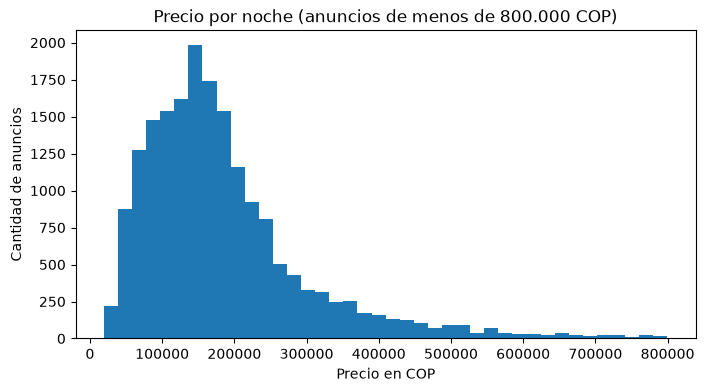

Anuncios que no caben en el gráfico (800.000 COP o más): 412


,room_type,accommodates,precio
17185,Entire home/apt,2,448176567.0
17227,Private room,2,421287834.0
17238,Private room,2,421287834.0
17240,Private room,4,421287834.0
17241,Private room,2,418047397.0


In [13]:
plt.figure(figsize=(8, 4))
plt.hist(precio[precio < 800000], bins=40)
plt.title("Precio por noche (anuncios de menos de 800.000 COP)")
plt.xlabel("Precio en COP")
plt.ylabel("Cantidad de anuncios")
plt.show()

print("Anuncios que no caben en el gráfico (800.000 COP o más):", (precio >= 800000).sum())
df_listings.nlargest(5, "precio")[["room_type", "accommodates", "precio"]]

**Interpretación.** El precio mediano es de unos 161.000 COP por noche, pero el promedio sube a 446.000 porque hay
precios altísimos (el máximo es de 448 millones). Por eso para resumir el precio usamos la mediana y no el promedio.

Con la regla del IQR salen 1.410 anuncios atípicos (7 %), todos por encima de unos 411.000 COP. Al mirar los más caros
vimos habitaciones privadas para 1 a 4 personas con precios de cientos de millones, que seguramente son errores al
digitar el precio. Pero no todos los atípicos son errores (puede haber propiedades de lujo), así que **no los borramos**:
los marcamos en una columna `precio_atipico`.

In [14]:
print("minimum_nights más comunes:")
print(df_listings["minimum_nights"].value_counts().head(5))
print()
print("maximum_nights más altos:", df_listings["maximum_nights"].nlargest(5).tolist())

minimum_nights más comunes:
minimum_nights
1.0     9923
2.0     3549
30.0    3240
3.0     1056
5.0      300
Name: count, dtype: int64

maximum_nights más altos: [2147483647.0, 2147483647.0, 2147483647.0, 2147483647.0, 1241244.0]


**Interpretación.** La mayoría de anuncios pide entre 1 y 3 noches mínimas, pero hay un grupo grande en 30 noches, que
son alquileres mensuales. No es un error, es otro tipo de anuncio.

En `maximum_nights` hay unos pocos anuncios con 2.147.483.647, que es un valor "sin límite" del sistema y no una cantidad
real. Los limitamos a 1.125 noches, que es lo máximo que permite reservar Airbnb.

In [15]:
disponibilidad = df_listings["availability_365"]
print(disponibilidad.describe())

# misma regla del IQR que usamos con el precio
q1 = disponibilidad.quantile(0.25)
q3 = disponibilidad.quantile(0.75)
limite_inferior = q1 - 1.5 * (q3 - q1)
print("Límite inferior:", round(limite_inferior), "días")
print("Anuncios por debajo del límite:", (disponibilidad < limite_inferior).sum())
print("Anuncios con 365 días disponibles:", (disponibilidad == 365).sum())
print("Anuncios con 0 días disponibles:", (disponibilidad == 0).sum())

count    19187.000000
mean       306.947725
std         82.073601
min          0.000000
25%        269.000000
50%        349.000000
75%        363.000000
max        365.000000
Name: availability_365, dtype: float64
Límite inferior: 128 días
Anuncios por debajo del límite: 1129
Anuncios con 365 días disponibles: 3508
Anuncios con 0 días disponibles: 4


**Interpretación.** `availability_365` va de 0 a 365, o sea que no tiene valores imposibles. La mayoría de anuncios aparece
disponible casi todo el año (la mediana es de 349 días) y cerca de 3.500 tienen los 365 días. Los atípicos por la regla del
IQR son los que tienen muy pocos días disponibles, que son anuncios muy reservados o que el anfitrión bloqueó. No son errores,
así que en esta columna no hay nada que corregir.

## 4. Distribuciones y relaciones

### Oferta por localidad y tipo de alojamiento

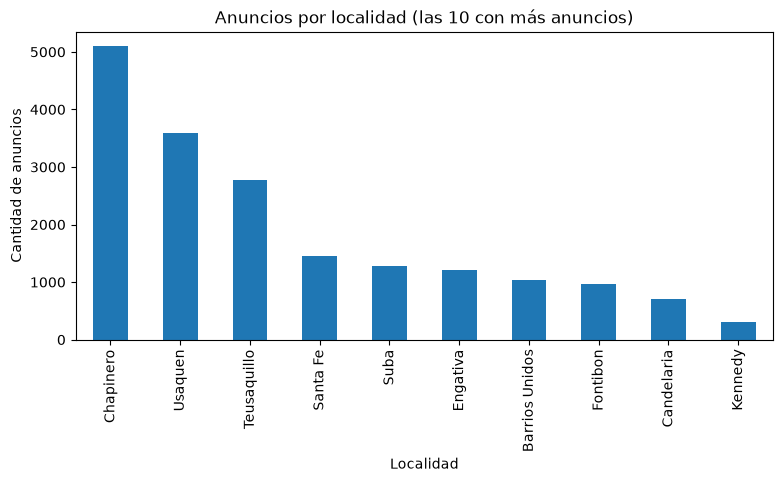

Precio mediano en esas localidades:
neighbourhood_cleansed
Chapinero         199111.87
Usaquen           194001.00
Teusaquillo       136479.00
Santa Fe          149562.66
Suba              136941.33
Engativa          112347.00
Barrios Unidos    142647.50
Fontibon          136942.00
Candelaria        136941.24
Kennedy           108206.50
Name: precio, dtype: float64


In [16]:
top_localidades = df_listings["neighbourhood_cleansed"].value_counts().head(10)

top_localidades.plot(kind="bar", figsize=(9, 4))
plt.title("Anuncios por localidad (las 10 con más anuncios)")
plt.xlabel("Localidad")
plt.ylabel("Cantidad de anuncios")
plt.show()

print("Precio mediano en esas localidades:")
print(df_listings.groupby("neighbourhood_cleansed")["precio"].median().loc[top_localidades.index])

In [17]:
print(df_listings["room_type"].value_counts())
df_listings.groupby("room_type")["precio"].agg(["median", "mean"]).round(0)

room_type
Entire home/apt    13865
Private room        5172
Shared room          117
Hotel room            33
Name: count, dtype: int64


,median,mean
room_type,,
Entire home/apt,182589.0,333542.0
Hotel room,193048.0,253385.0
Private room,91295.0,759385.0
Shared room,41453.0,60082.0


**Interpretación.** Chapinero, Usaquén y Teusaquillo reúnen cerca del 60 % de los anuncios. Chapinero y Usaquén también
tienen los precios medianos más altos (alrededor de 195.000 COP), pero Teusaquillo tiene muchos anuncios y un precio
mediano más bajo (unos 136.000 COP). Kennedy y Engativá son las más económicas.

Por tipo de alojamiento, el 72 % son viviendas completas y el 27 % habitaciones privadas; habitación compartida y hotel
son muy pocos. En las habitaciones privadas el promedio (759.000) es mucho mayor que la mediana (91.000), que son los
precios errados que vimos antes.

### Relación del precio con otras variables

In [18]:
variables = ["accommodates", "beds", "bedrooms", "minimum_nights", "review_scores_rating"]
df_listings[variables + ["precio"]].corr(method="spearman")["precio"].drop("precio").round(2)

accommodates            0.50
beds                    0.36
bedrooms                0.32
minimum_nights         -0.18
review_scores_rating    0.05
Name: precio, dtype: float64

**Interpretación.** Usamos la correlación de Spearman porque los precios extremos dañan la correlación normal.
El precio sube con la capacidad: `accommodates` es la más relacionada (0,50), seguida de `beds` y `bedrooms` (cerca de
0,3). Con `minimum_nights` la relación es negativa (-0,18): a más noches mínimas, menor precio por noche, como pasa en los
alquileres mensuales. La calificación casi no tiene relación con el precio (0,05).

### Reseñas en el tiempo

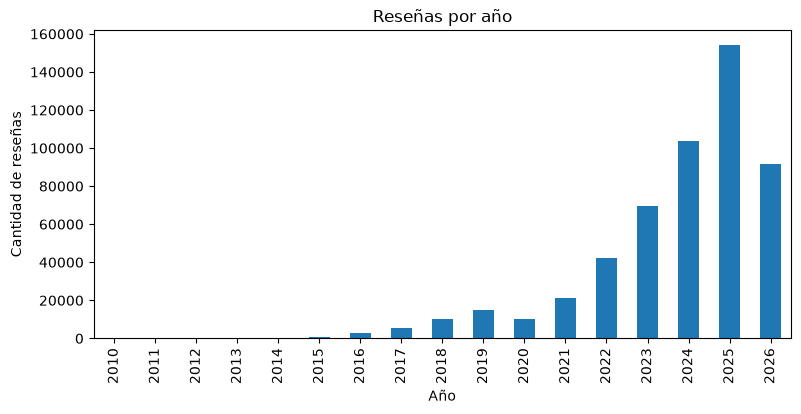

Comentarios con etiquetas HTML: 69375 de 527731


In [19]:
resenas_por_anio = df_reviews["date"].dt.year.value_counts().sort_index()

resenas_por_anio.plot(kind="bar", figsize=(9, 4))
plt.title("Reseñas por año")
plt.xlabel("Año")
plt.ylabel("Cantidad de reseñas")
plt.show()

con_html = df_reviews["comments"].astype(str).str.contains("<br", regex=False)
print("Comentarios con etiquetas HTML:", con_html.sum(), "de", len(df_reviews))

**Interpretación.** Las reseñas crecen año a año hasta 2025. En 2020 hay una caída que seguramente fue por la pandemia,
y 2026 solo llega hasta junio. Antes de 2016 casi no hay reseñas.

Además, cerca del 13 % de los comentarios tiene etiquetas HTML como `<br/>`, que hay que quitar para que el texto se
pueda leer bien.

### Disponibilidad por mes

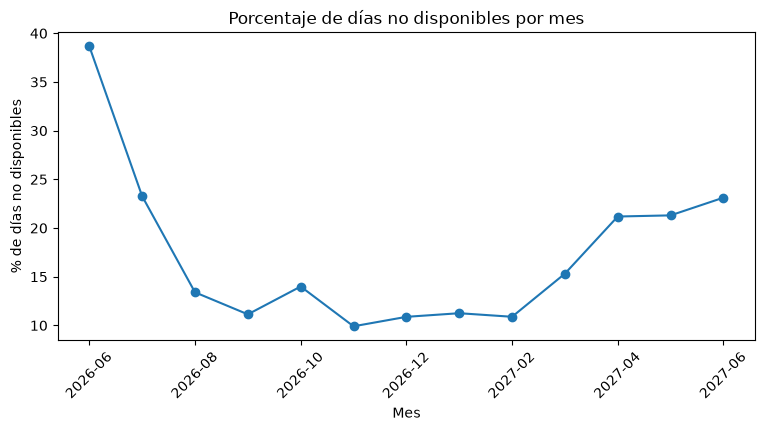

% no disponible por día de la semana (lunes a domingo): [15.9, 15.4, 15.5, 16.0, 16.4, 16.3, 15.7]


In [20]:
no_disponible = (1 - df_calendar.groupby(df_calendar["date"].dt.to_period("M"))["available"].mean()) * 100
no_disponible.index = no_disponible.index.astype(str)

no_disponible.plot(kind="line", marker="o", figsize=(9, 4))
plt.title("Porcentaje de días no disponibles por mes")
plt.xlabel("Mes")
plt.ylabel("% de días no disponibles")
plt.xticks(rotation=45)
plt.show()

por_dia = (1 - df_calendar.groupby(df_calendar["date"].dt.dayofweek)["available"].mean()) * 100
print("% no disponible por día de la semana (lunes a domingo):", por_dia.round(1).tolist())

**Interpretación.** El porcentaje de días no disponibles empieza alto (casi 39 % en junio de 2026), baja hasta
noviembre (cerca de 10 %) y vuelve a subir a finales de la serie. Esto pasa más que todo porque los días cercanos ya
están reservados y los lejanos todavía no, así que no lo tomamos como temporada alta o baja.

Por día de la semana casi no hay diferencia. Como además el calendario es una sola "foto" del 21 de junio de 2026, el
`porcentaje_ocupacion` lo tomamos como un indicador de no disponibilidad y no como ocupación real.

## 5. Posibles transformaciones

### Campos anidados

In [21]:
print("Ejemplo de amenities:", df_listings["amenities"].iloc[0][:5])
cantidad = df_listings["amenities"].map(len)
print("Amenidades por anuncio -> mínimo:", cantidad.min(), "| mediana:", cantidad.median(), "| máximo:", cantidad.max())
print("Tipo de price_quote_raw:", type(df_listings["price_quote_raw"].iloc[0]).__name__)

todas = pd.Series([a for lista in df_listings["amenities"] for a in lista]).value_counts()
(todas.head(8) / len(df_listings) * 100).round(1)

print()
print("Columnas del host:", [col for col in df_listings.columns if col.startswith("host")])


Ejemplo de amenities: ['Blender', 'Luggage dropoff allowed', 'Long term stays allowed', 'Children’s dinnerware', 'Drying rack for clothing']
Amenidades por anuncio -> mínimo: 0 | mediana: 26.0 | máximo: 90
Tipo de price_quote_raw: dict



Columnas del host: ['host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_is_superhost', 'host_picture_url', 'host_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified']


**Interpretación.** `amenities` es una lista de hasta 90 elementos por anuncio. La pasamos a texto y creamos columnas
de 1 o 0 para algunas amenidades: wifi, cocina, aire acondicionado, estacionamiento, lavadora y piscina. `price_quote_raw`
es un diccionario cuyos datos ya están en otras columnas (y todo está en COP), así que la eliminamos.

**Información del host.** Las columnas del host (`host_name`, `host_is_superhost`, `host_identity_verified`, etc.) ya
vienen planas, no hay nada anidado que desanidar. De ahí nos sirven pocas: `host_is_superhost`, `host_identity_verified`
y `host_listings_count`. `host_verifications` no sirve (todo es `'None'`) y `host_about` tiene casi la mitad de nulos.


### Agrupar datos

In [22]:
resumen_mensual = df_calendar.groupby(
    ["listing_id", df_calendar["date"].dt.year.rename("anio"), df_calendar["date"].dt.month.rename("mes")]
)["available"].agg(["size", "sum"])

print("Calendar:", len(df_calendar), "filas -> resumen por anuncio y mes:", len(resumen_mensual), "filas")
resumen_mensual.head()

Calendar: 7003255 filas -> resumen por anuncio y mes: 249431 filas


size  sum
listing_id anio mes           
27841      2026 6       9    0
                7      31    0
                8      31    0
                9      30    0
                10     31    0

**Interpretación.** Calendar tiene más de 7 millones de filas y no cabe en Excel (el límite es un poco más de un
millón). Resumido por anuncio y mes quedan unas 249.000 filas, con los días totales, disponibles y ocupados. Con eso
armamos la tabla `Calendar_Mensual`.

### Formatos

In [23]:
print("Ejemplos de price:", df_listings["price"].head(3).tolist())
print("Tipo de las fechas:", df_listings["first_review"].dtype, "|", df_calendar["date"].dtype)
print("Tipo de host_is_superhost:", df_listings["host_is_superhost"].dtype)
print("Descripciones con HTML:", df_listings["description"].astype(str).str.contains("<br", regex=False).sum())
print("Ejemplos de bathrooms_text:", df_listings["bathrooms_text"].dropna().unique()[:4].tolist())
print("bathrooms nulos:", df_listings["bathrooms"].isnull().sum())

Ejemplos de price: ['$284,294.01', '$215,000.00', '$99,196.10']
Tipo de las fechas: datetime64[us] | datetime64[us]
Tipo de host_is_superhost: bool
Descripciones con HTML: 8045
Ejemplos de bathrooms_text: ['2.5 baths', '1 bath', '2 baths', '1 private bath']
bathrooms nulos: 1066


**Interpretación.**

- **Precio:** pasarlo a número. Todo está en COP, así que no hay que convertir monedas. Como el precio tiene una cola
  muy larga, los rangos los hicimos por cuartiles y no con cortes fijos.
- **Fechas:** dejarlas como `YYYY-MM-DD` sin hora y sacar `anio`, `mes`, `dia`, `trimestre` y `dia_semana`.
- **Booleanos:** cambiar `True/False` por 1/0.
- **Texto:** quitar el HTML y espacios de sobra en descripciones y comentarios.
- **Baños:** `bathrooms` tiene unos 1.000 nulos, pero `bathrooms_text` (por ejemplo "2.5 baths") sí trae el dato, así
  que sacamos el número a una columna `banos`.

## 6. Hallazgos y decisiones

En general los datos están bastante bien: no hay duplicados, Calendar está completo y las llaves son consistentes. Los
problemas principales son el precio (texto, nulos y valores extremos), el valor raro de `maximum_nights`, los campos
anidados y el texto con HTML.

| Hallazgo | Decisión | Método en `transformacion.py` |
|---|---|---|
| `price` es texto con `$` y comas | Pasarlo a número | `normalizar_precios` |
| 195 anuncios sin precio | Eliminarlos | `limpiar_nulos_duplicados` |
| Precios extremos | Marcarlos, no borrarlos | `marcar_atipicos` |
| Precio en COP con cola larga | Rangos por cuartiles | `categorizar_precios` |
| Nulos de reseñas | No rellenarlos | `imputar_nulos` (solo las columnas que elegimos) |
| Texto opcional con nulos | "Sin información" | `imputar_nulos` |
| `bedrooms`, `beds` y baños con nulos | Mediana | `imputar_nulos` |
| `host_verifications` solo dice `'None'` | Eliminar la columna | `eliminar_columnas_vacias` |
| `amenities` es una lista | Texto y columnas 1/0 | `expandir_amenidades` |
| Baños solo como texto | Columna numérica `banos` | `extraer_banos` |
| `maximum_nights` con 2.147.483.647 | Limitar a 1.125 | `limitar_valores` |
| Booleanos `True/False` | Pasarlos a 1/0 | `normalizar_booleanos` |
| Fechas con hora | Formato `YYYY-MM-DD` y variables de tiempo | `transformar_fechas` |
| HTML en comentarios y descripciones | Quitar etiquetas | `estandarizar_texto` |
| Calendar muy grande | Resumen mensual | `agrupar_calendario_mensual` |

**Para qué sirven estos datos:** para ver la oferta y los precios por localidad y tipo de alojamiento, separar las
estancias cortas de las mensuales y ver cómo van las reseñas.

**Limitaciones:** el calendario es una sola foto y no tiene precio por día, "no disponible" mezcla reservas con
bloqueos, y hay que filtrar `precio_atipico` antes de calcular promedios de precio.